In [30]:
cd ./wrkDir/s19/s19-1/

/work/xiangchong.li/work/galSim-HSC/s19/s19-1


In [32]:
%pylab inline
import gc
import fitsio
import treecorr
import numpy as np
import catutil
import matplotlib.lines as mlines

import astropy.table as astTable
anaDir='./anaCat_newS19Mask_fdeltacut/'
pltDir=os.path.join(anaDir,'plot/optimize_weight')
assert os.path.isdir(anaDir)
assert os.path.isdir(pltDir)

Populating the interactive namespace from numpy and matplotlib


In [33]:
del dataG
names=['i_cmodel_flux','i_cmodel_fluxerr',\
       'i_hsmshaperegauss_resolution','i_hsmshaperegauss_derived_weight']
nzs    =   4
dataG  =   []
Dir    =   '/work/xiangchong.li/work/cosmicShear/s19a/'
for fieldname in catutil.field_names:
    # mock catalog (will copy v2 to GW and idark)
    catFname=  os.path.join(Dir,'g3Sim/catalog_obs_reGaus_no_m/%s_no_m.fits' %(fieldname))
    data   =   fitsio.read(catFname)[names]
    dataG.append(data)
    del data
    gc.collect()
dataG  =  np.hstack(dataG)

In [34]:
snr=dataG['i_cmodel_flux']/dataG['i_cmodel_fluxerr']
msk=snr<80.
snr=snr[msk]
dataG=dataG[msk]
res=dataG['i_hsmshaperegauss_resolution']
weight=dataG['i_hsmshaperegauss_derived_weight']
nbin_1d=20
# Now set up sliding window definition
# Only use the first in pair
snr_lower, snr_upper, res_lower, res_upper = \
    catutil.sliding_window_def(snr,res,n_gal=100*100,n_bin_1d=nbin_1d)
mean_res = np.zeros((nbin_1d, nbin_1d))
mean_snr = np.zeros((nbin_1d, nbin_1d))
mean_w   = np.zeros((nbin_1d, nbin_1d))

for i in range(len(snr_lower)):
    for j in range(len(snr_lower)):
        bin_mask = \
            (snr >= snr_lower[i]) & \
            (snr < snr_upper[i]) & \
            (res >= res_lower[i,j]) & \
            (res < res_upper[i,j])
        mean_snr[i,j] = \
            np.sum(weight[bin_mask]*snr[bin_mask])/ \
            np.sum(weight[bin_mask])
        mean_res[i,j] = \
            np.sum(weight[bin_mask]*res[bin_mask])/ \
            np.sum(weight[bin_mask])
        mean_w[i,j] = \
            np.average(weight[bin_mask])

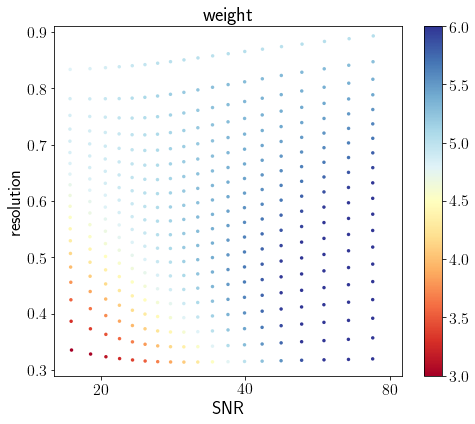

In [41]:
vmin = 3.
vmax = 6.
cm  = plt.cm.get_cmap('RdYlBu')
fig = plt.figure(figsize=(7,6))
ax = fig.add_subplot(111)
sc = ax.scatter(mean_snr, mean_res, c=mean_w, cmap=cm,
    vmin=vmin, vmax=vmax, edgecolors='none',s=12.)
ax.set_xscale('symlog')
ax.set_xlim(left=16,right=85.)
ax.set_ylim(0.29,0.91)
ax.set_xlabel('SNR')
ax.set_ylabel('resolution')
plt.title('weight',fontsize=20)
ax.set_xticks((20,40,80))
ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
cbar=plt.colorbar(sc)
plt.tight_layout()
plt.savefig(os.path.join(pltDir,'weight_cat_2d.png'))
plt.savefig(os.path.join(pltDir,'weight_cat_2d.pdf'))